# Country Clustering — Unsupervised Segmentation of 167 Countries

## 1. Problem
Group countries with similar socio-economic and health profiles **without any labels**, and check whether the data supports
the intuitive split into three groups: developed, developing and least developed countries.

One algorithm from each main family of clustering methods is compared:

| Family | Algorithm | Why it is useful |
|---|---|---|
| Partitional | **K-Means** | the most widely used clustering algorithm |
| Hierarchical | **Agglomerative Clustering** | builds a dendrogram and shows the relationships between clusters |
| Density-based | **DBSCAN** | finds irregularly shaped clusters and outliers |
| Probabilistic | **Gaussian Mixture Model (EM)** | clustering based on probability distributions |

## 2. Data
Dataset: [Unsupervised Learning on Country Data (Kaggle)](https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data/data) —
167 countries × 9 numeric indicators (child mortality, exports, health spending, imports, income, inflation, life expectancy,
fertility, GDP per capita). Column definitions are in `data/data-dictionary.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import numpy as np


In [2]:
data = pd.read_csv("../data/Country-data.csv")

In [3]:
data.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


In [5]:
data.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


In [6]:
data.isnull().sum()

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

## 3. Exploratory Data Analysis
No missing values. The `country` column is a name, not a feature, so it is dropped before the analysis.

In [7]:
data = data.drop(columns=["country"])

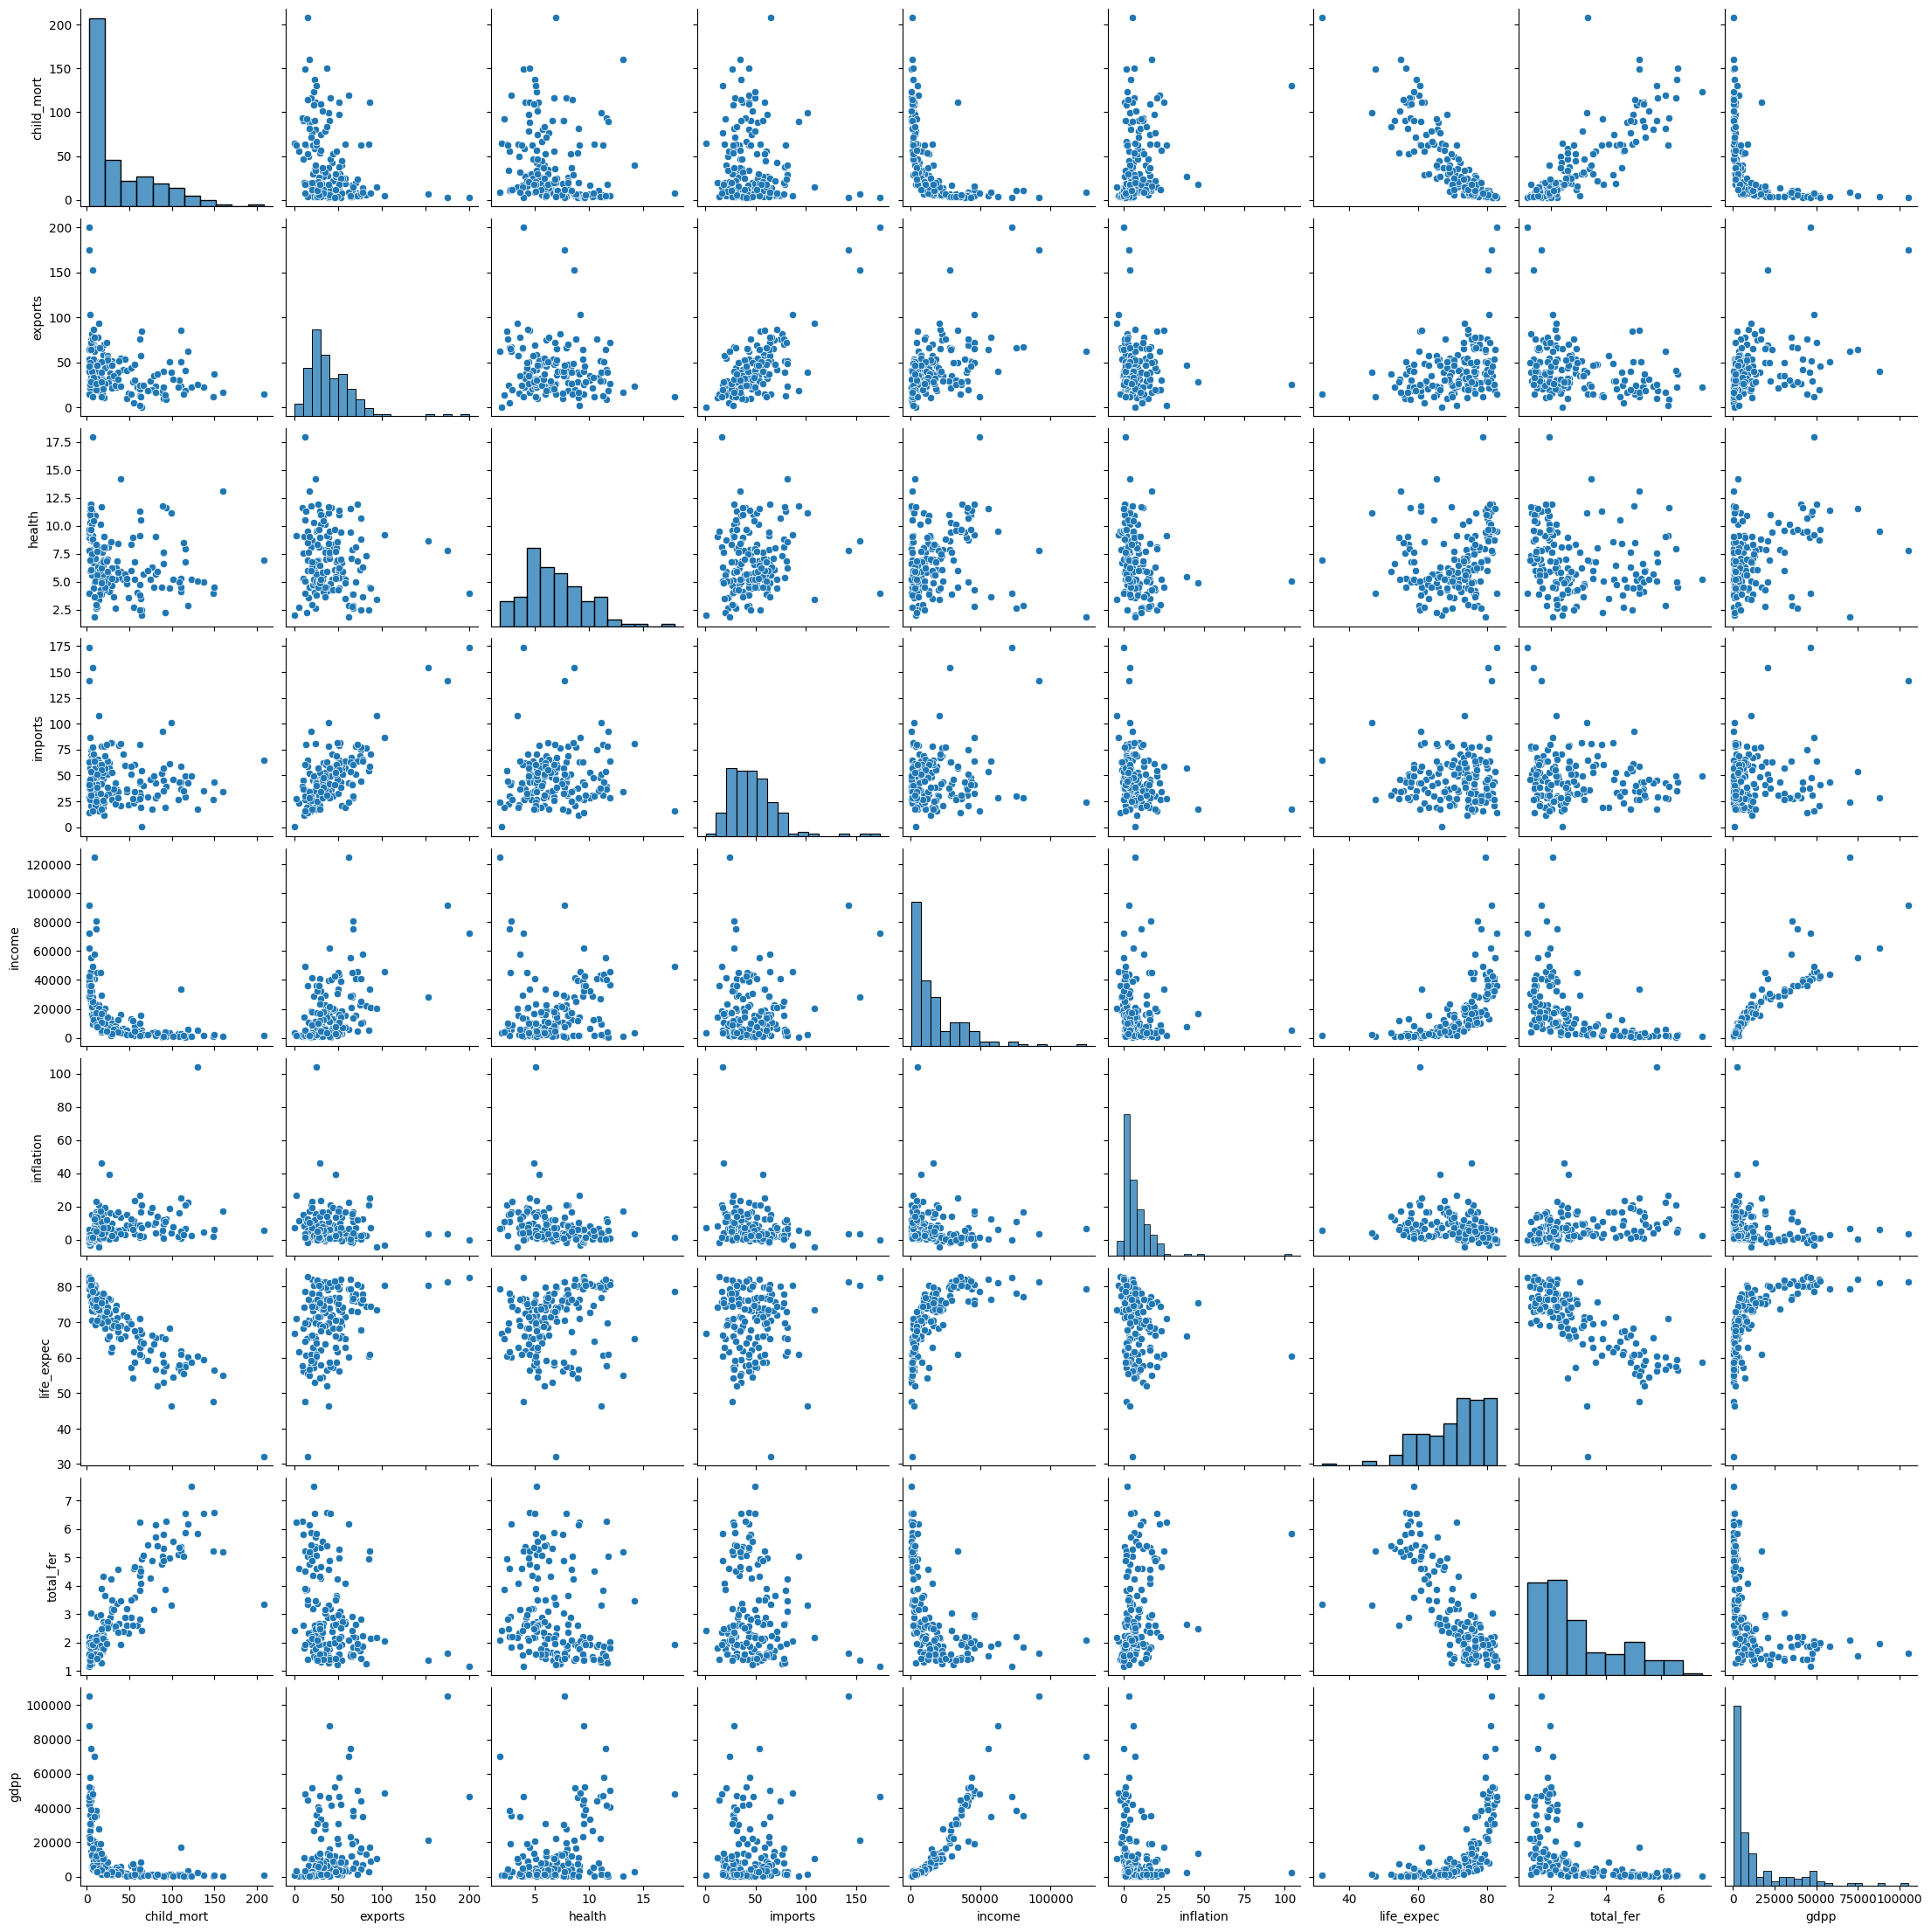

In [8]:
sns.pairplot(data)

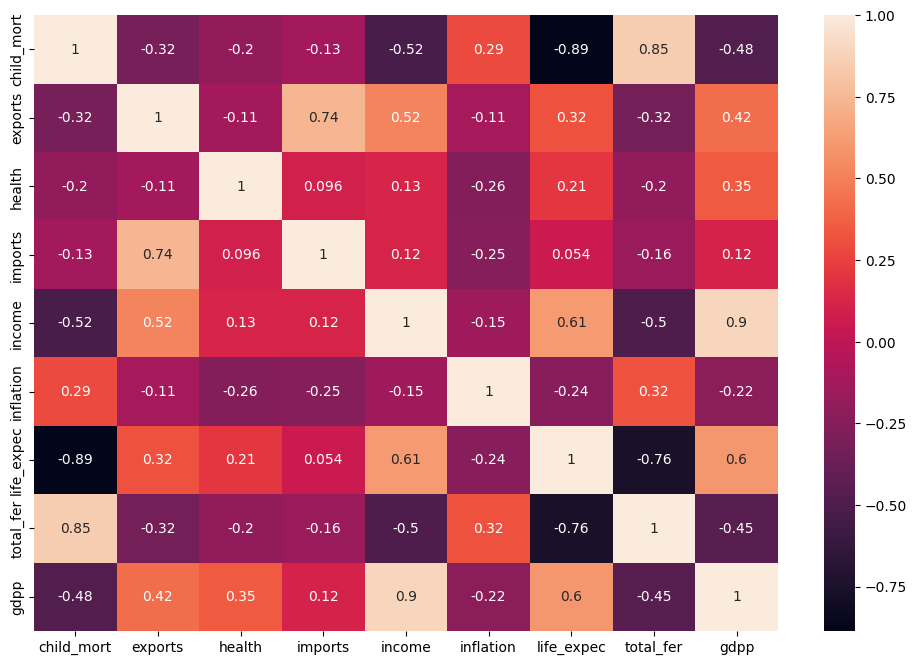

In [9]:
plt.figure(figsize=(12,8))
sns.heatmap(data.corr(), annot=True)        
plt.show()

array([[<Axes: title={'center': 'child_mort'}>,
        <Axes: title={'center': 'exports'}>,
        <Axes: title={'center': 'health'}>],
       [<Axes: title={'center': 'imports'}>,
        <Axes: title={'center': 'income'}>,
        <Axes: title={'center': 'inflation'}>],
       [<Axes: title={'center': 'life_expec'}>,
        <Axes: title={'center': 'total_fer'}>,
        <Axes: title={'center': 'gdpp'}>]], dtype=object)

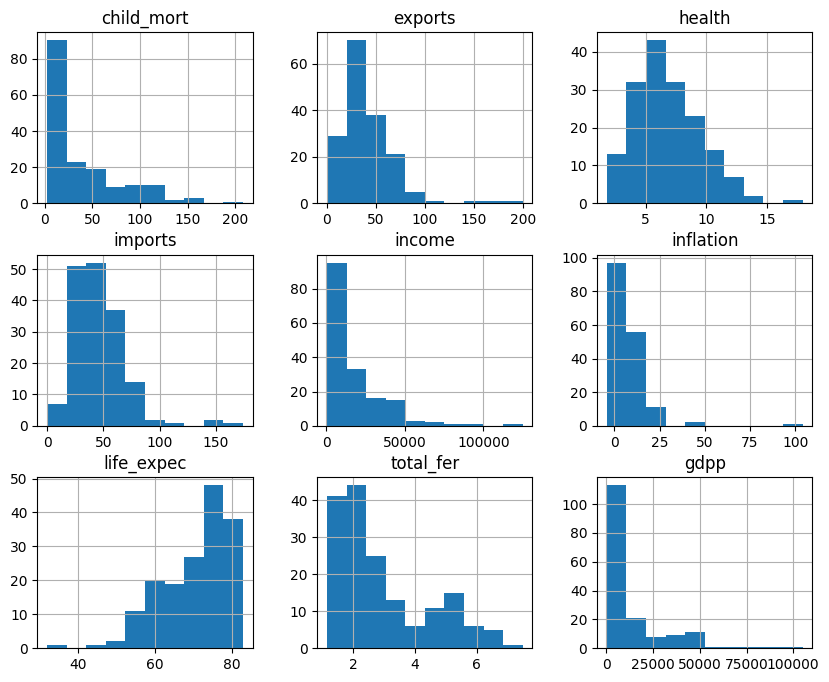

In [10]:
data.hist(figsize=(10,8))

<Axes: >

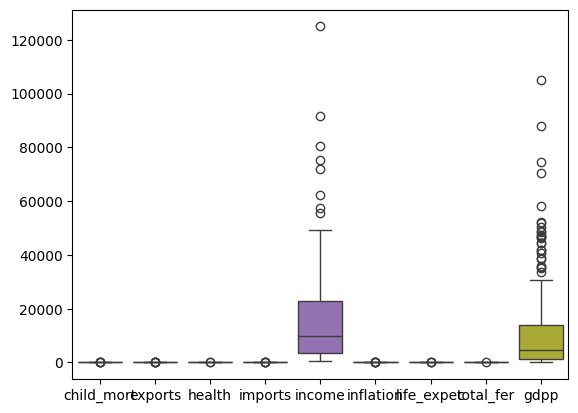

In [11]:
sns.boxplot(data=data)

### Correlation analysis

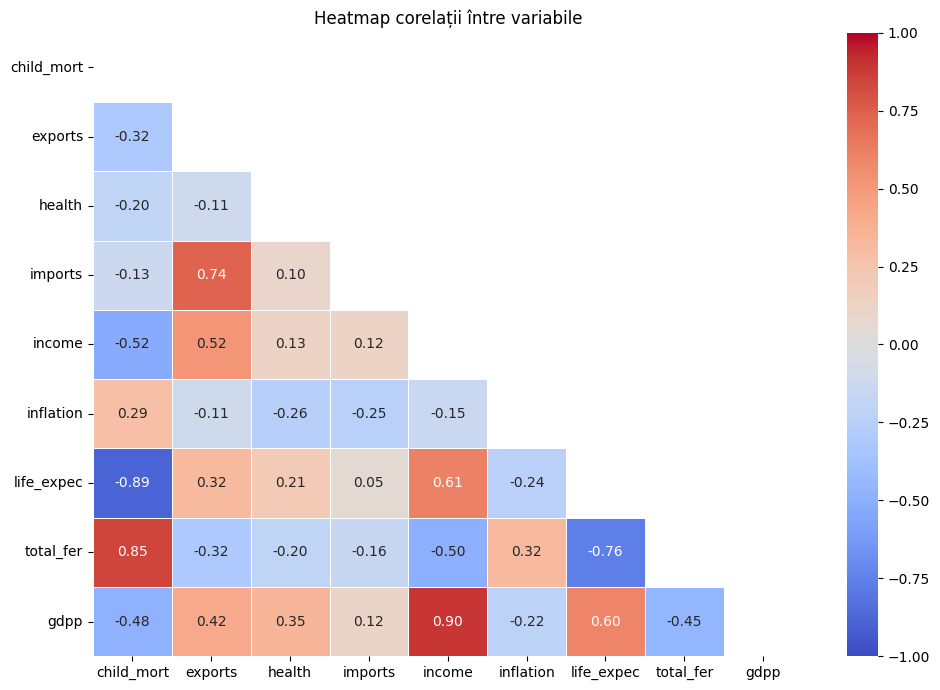

In [12]:
plt.figure(figsize=(10, 7))
corr = data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", mask=mask,
            linewidths=0.5, vmin=-1, vmax=1)
plt.title("Heatmap corelații între variabile")
plt.tight_layout()
plt.show()


## 4. Preprocessing — scaling + PCA
`StandardScaler` is essential before clustering: variables on very different scales (e.g. `gdpp` up to 105,000 vs `health` up to 17.9)
would otherwise dominate the distance computations.
PCA with 2 components is used **only for 2D visualization**; all clustering algorithms run on the 9 scaled features.

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

# PCA for 2D visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Varianta explicată de PCA: {pca.explained_variance_ratio_[0]*100:.1f}% + {pca.explained_variance_ratio_[1]*100:.1f}% = {sum(pca.explained_variance_ratio_)*100:.1f}%")

Varianta explicată de PCA: 46.0% + 17.2% = 63.1%


## 5. Modeling

### 5.1 Choosing K — Elbow method (K-Means)

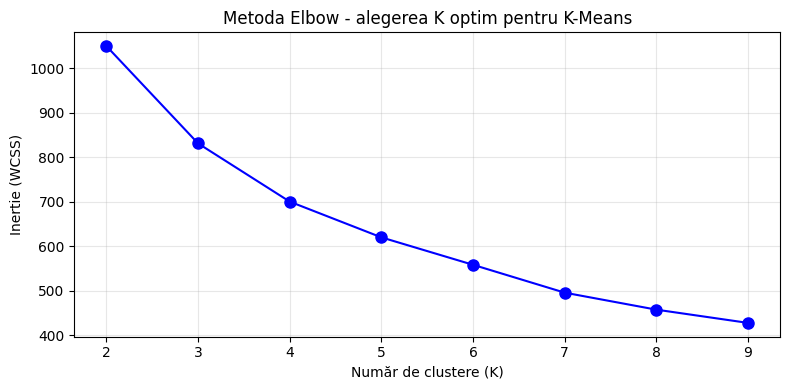

👉 K optim = punctul unde curba 'se îndoaie' - de obicei K=3 pentru acest dataset


In [14]:
inertii = []
K_range = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertii.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertii, 'bo-', markersize=8)
plt.xlabel("Număr de clustere (K)")
plt.ylabel("Inertie (WCSS)")
plt.title("Metoda Elbow - alegerea K optim pentru K-Means")
plt.xticks(K_range)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("👉 K optim = punctul unde curba 'se îndoaie' - de obicei K=3 pentru acest dataset")


### 5.2 K-Means (k = 2…5)

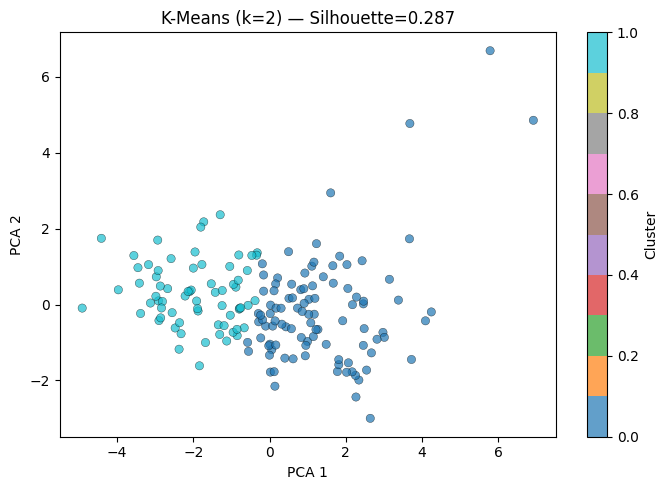

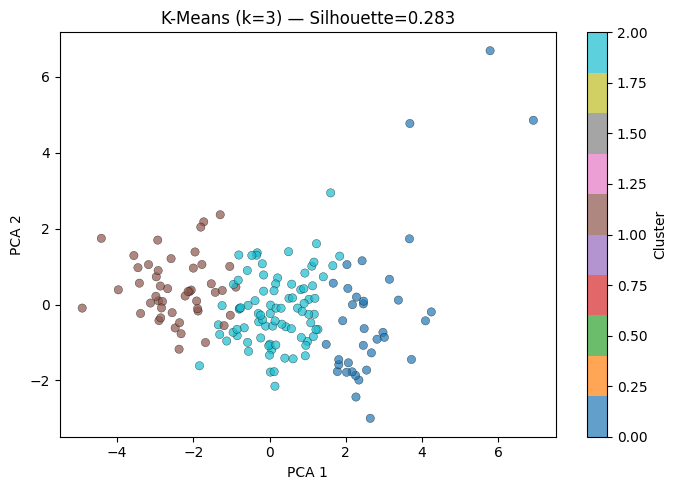

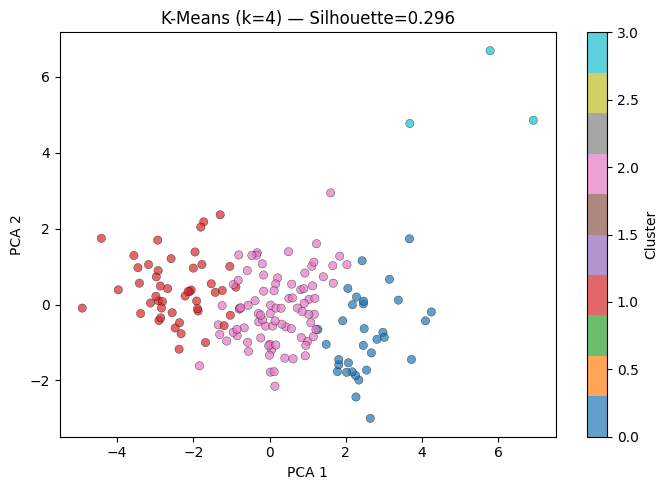

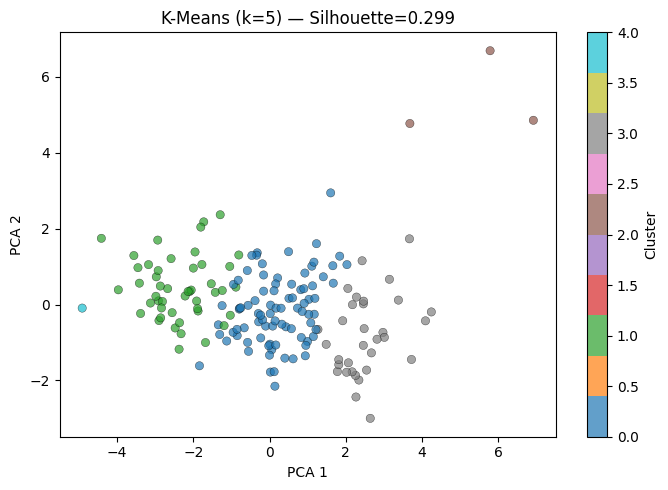

In [15]:
results = []

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    results.append(["KMeans", k, score, 0])
    
    plt.figure(figsize=(7, 5))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", alpha=0.7, edgecolors='k', linewidths=0.3)
    plt.colorbar(scatter, label="Cluster")
    plt.title(f"K-Means (k={k}) — Silhouette={score:.3f}")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.tight_layout()
    plt.show()


### 5.3 Hierarchical Agglomerative Clustering (Ward linkage) + dendrogram

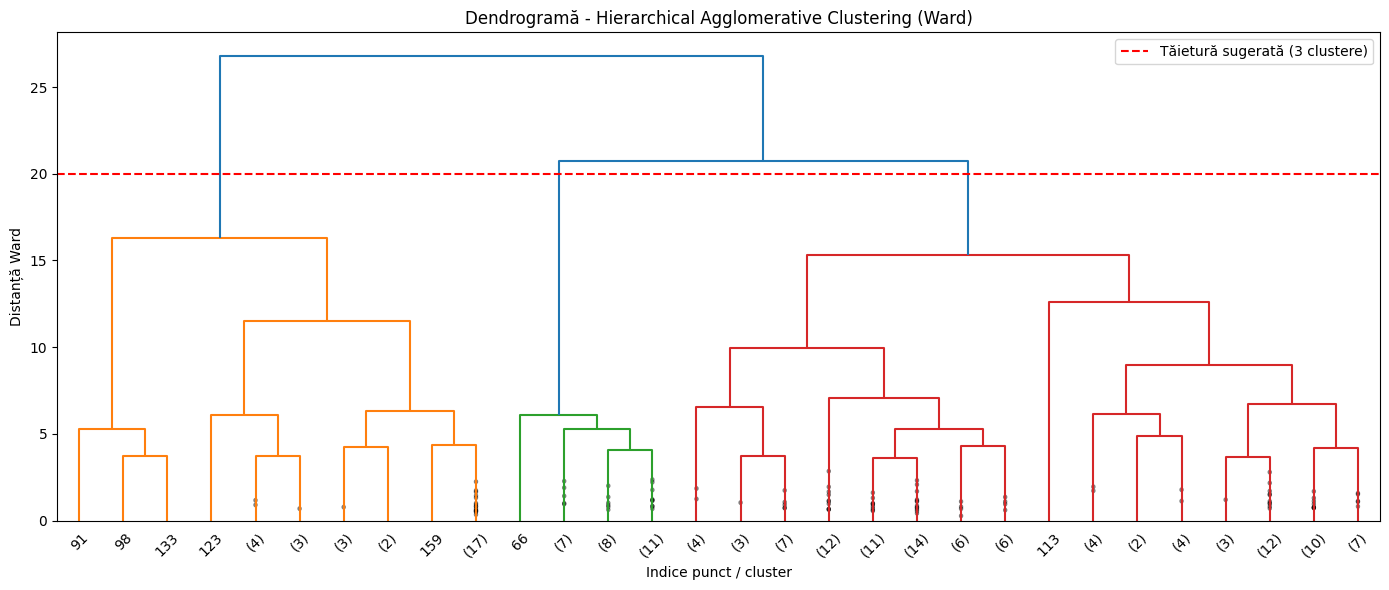

In [16]:
# Dendrogram
plt.figure(figsize=(14, 6))
Z = linkage(X_scaled, method='ward')
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=45, leaf_font_size=10, show_contracted=True)
plt.title("Dendrogramă - Hierarchical Agglomerative Clustering (Ward)")
plt.xlabel("Indice punct / cluster")
plt.ylabel("Distanță Ward")
plt.axhline(y=20, color='red', linestyle='--', label='Tăietură sugerată (3 clustere)')
plt.legend()
plt.tight_layout()
plt.show()

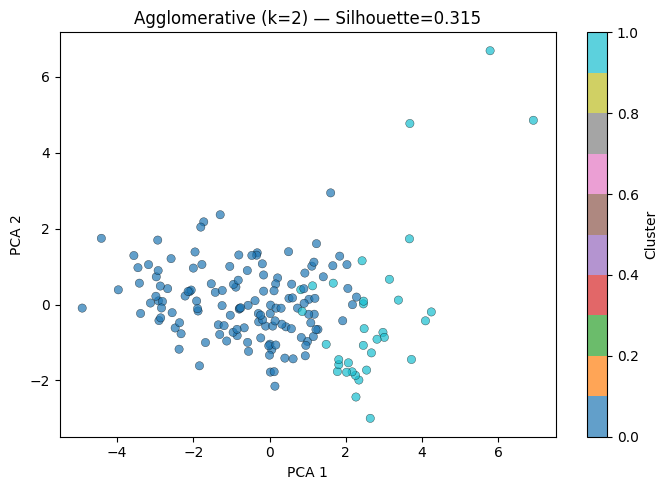

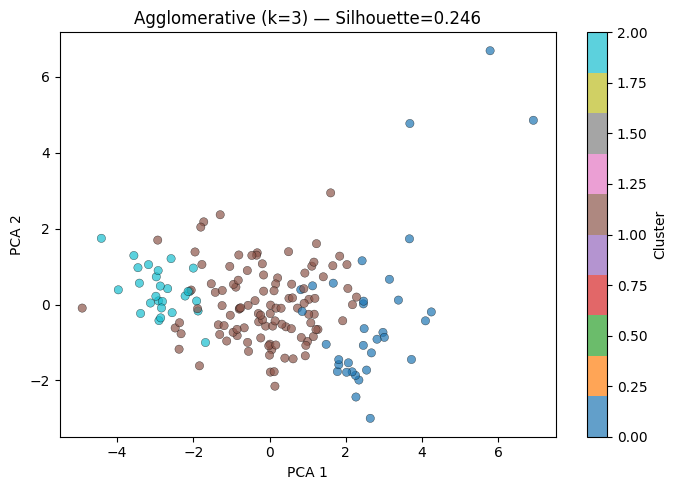

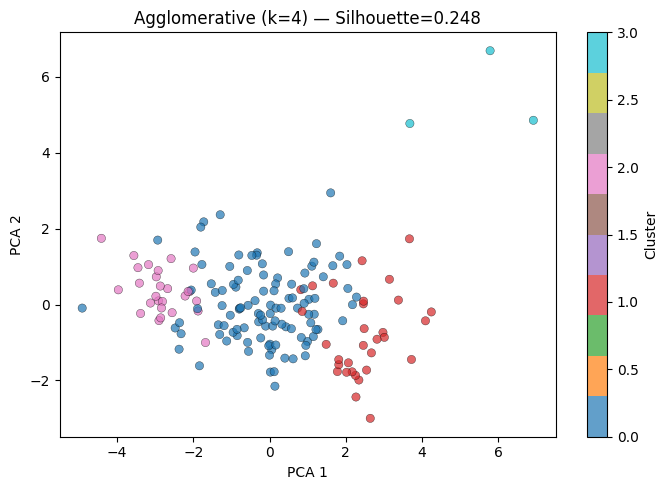

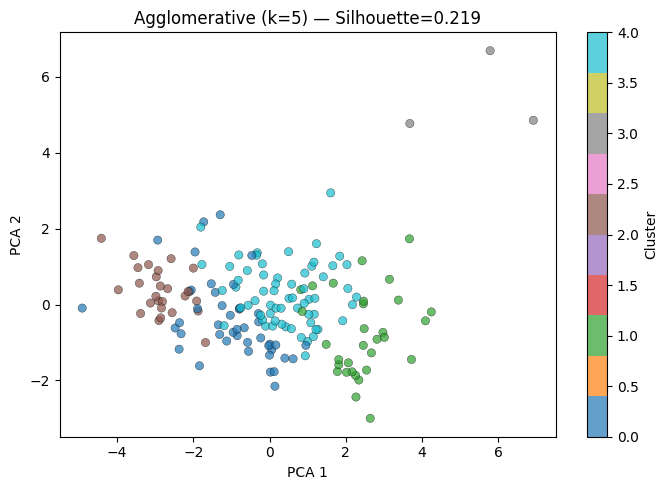

In [17]:
for k in range(2, 6):
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    results.append(["Agglomerative", k, score, 0])
    
    plt.figure(figsize=(7, 5))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", alpha=0.7, edgecolors='k', linewidths=0.3)
    plt.colorbar(scatter, label="Cluster")
    plt.title(f"Agglomerative (k={k}) — Silhouette={score:.3f}")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.tight_layout()
    plt.show()


### 5.4 DBSCAN
Grid search over `eps ∈ {0.3, 0.5, 0.7, 1.0, 1.5}` × `min_samples ∈ {3, 5, 10}`; only configurations with at least 2 clusters are kept.
Note: the silhouette score is computed **only on the points that are not labeled as noise** (`-1`).

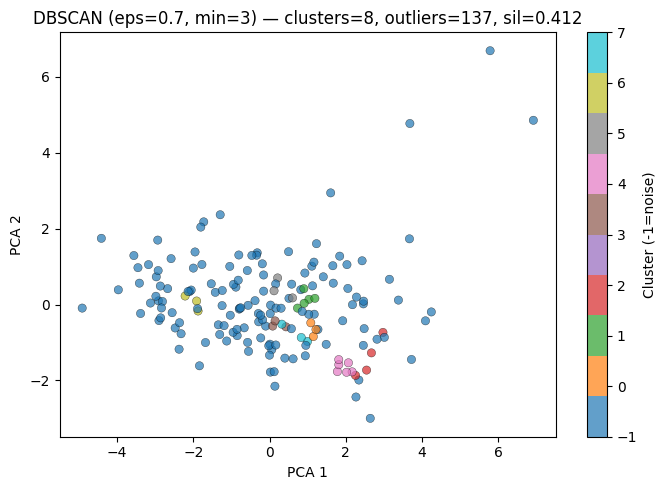

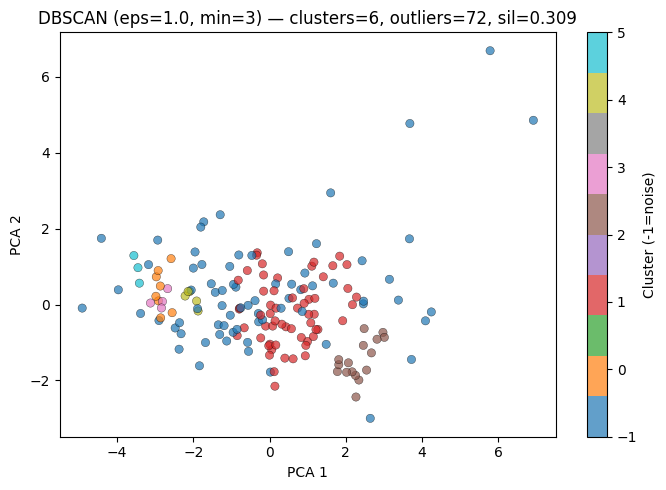

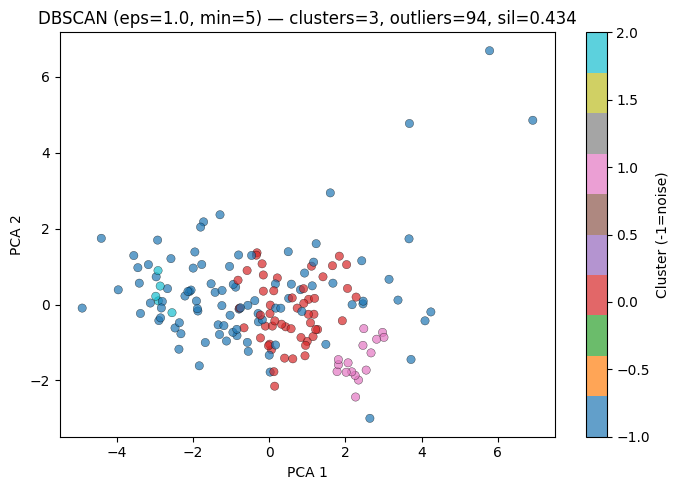

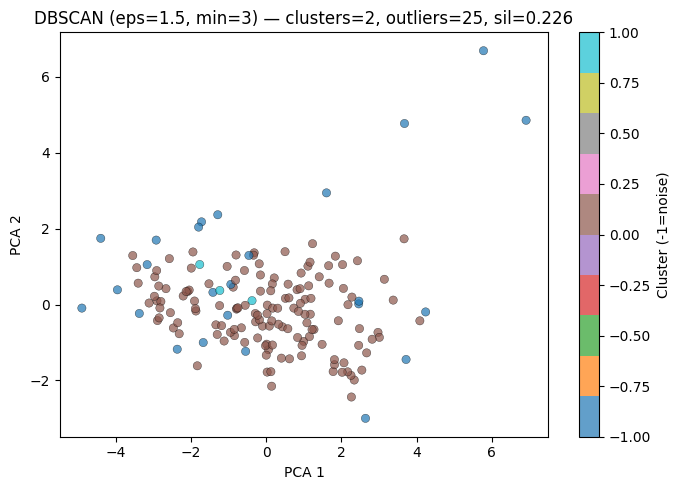

In [18]:
for eps in [0.3, 0.5, 0.7, 1.0, 1.5]:
    for min_samples in [3, 5, 10]:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_scaled)
        
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        if n_clusters < 2:
            continue
        
        mask = labels != -1
        if len(set(labels[mask])) < 2:
            continue
        
        score = silhouette_score(X_scaled[mask], labels[mask])
        n_outliers = list(labels).count(-1)
        results.append(["DBSCAN", n_clusters, score, n_outliers])
        
        plt.figure(figsize=(7, 5))
        scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", alpha=0.7, edgecolors='k', linewidths=0.3)
        plt.colorbar(scatter, label="Cluster (-1=noise)")
        plt.title(f"DBSCAN (eps={eps}, min={min_samples}) — clusters={n_clusters}, outliers={n_outliers}, sil={score:.3f}")
        plt.xlabel("PCA 1")
        plt.ylabel("PCA 2")
        plt.tight_layout()
        plt.show()


### 5.5 Gaussian Mixture Model (EM, k = 2…5)

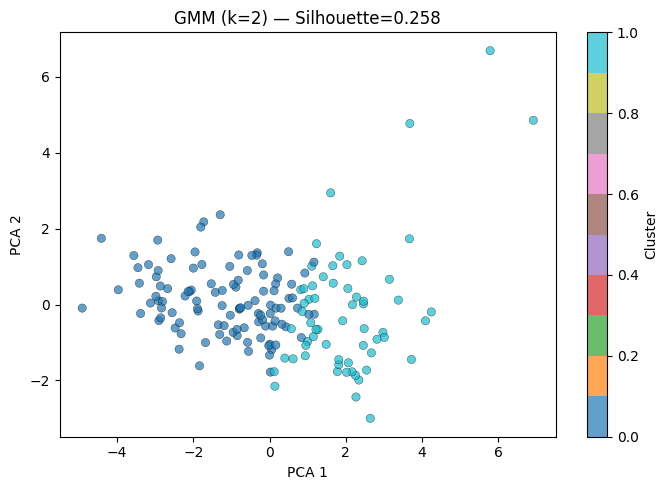

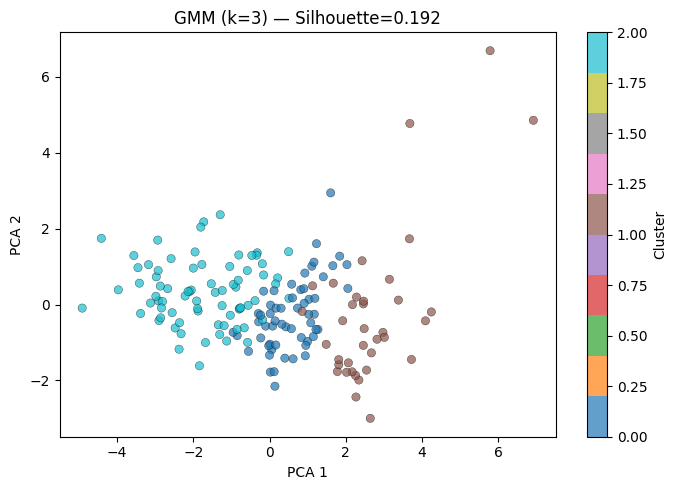

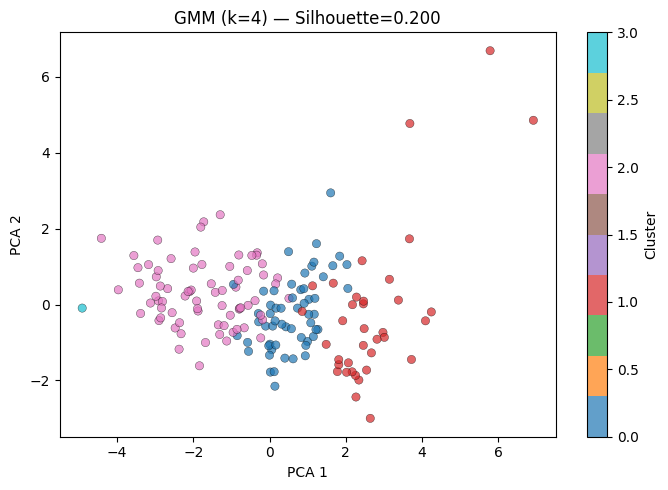

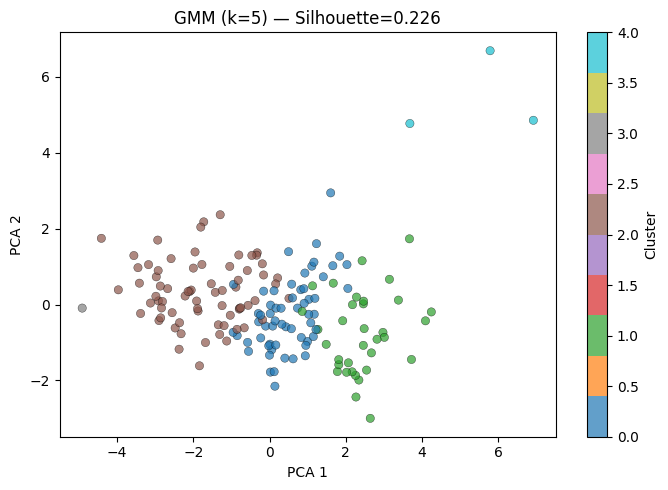

In [19]:
for k in range(2, 6):
    model = GaussianMixture(n_components=k, random_state=42)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    results.append(["GMM", k, score, 0])
    
    plt.figure(figsize=(7, 5))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", alpha=0.7, edgecolors='k', linewidths=0.3)
    plt.colorbar(scatter, label="Cluster")
    plt.title(f"GMM (k={k}) — Silhouette={score:.3f}")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.tight_layout()
    plt.show()


## 6. Evaluation

### 6.1 Comparison table (silhouette score)

In [20]:
results_df = pd.DataFrame(results, columns=["Model", "Nr_Clusters", "Silhouette", "Outliers"])
results_df = results_df.sort_values(by="Silhouette", ascending=False).reset_index(drop=True)
print(results_df.to_string())


            Model  Nr_Clusters  Silhouette  Outliers
0          DBSCAN            3    0.434453        94
1          DBSCAN            8    0.411797       137
2   Agglomerative            2    0.315313         0
3          DBSCAN            6    0.308836        72
4          KMeans            5    0.299259         0
5          KMeans            4    0.295952         0
6          KMeans            2    0.287357         0
7          KMeans            3    0.283296         0
8             GMM            2    0.257954         0
9   Agglomerative            4    0.248119         0
10  Agglomerative            3    0.245630         0
11            GMM            5    0.226410         0
12         DBSCAN            2    0.226141        25
13  Agglomerative            5    0.219330         0
14            GMM            4    0.199859         0
15            GMM            3    0.192331         0


**DBSCAN has the highest silhouette (0.434, eps = 1.0, min_samples = 5), but it labels 94 of the 167 countries as noise** —
the score only describes the remaining 73 countries, so this is not a useful segmentation of the dataset.
Among the methods that assign every country to a cluster, scores are close (0.19–0.32).

### 6.2 Best silhouette per algorithm

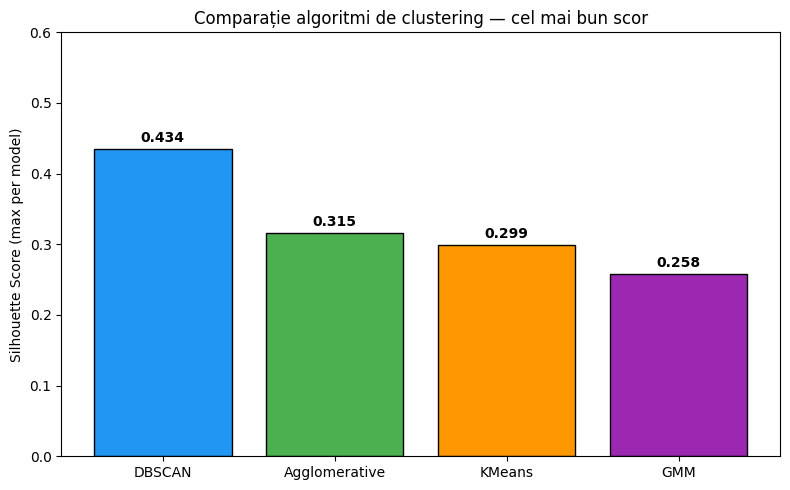

In [21]:
# Best score per algorithm
best_per_model = results_df.groupby("Model")["Silhouette"].max().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
bars = plt.bar(best_per_model.index, best_per_model.values, color=["#2196F3","#4CAF50","#FF9800","#9C27B0"], edgecolor='black')
plt.ylabel("Silhouette Score (max per model)")
plt.title("Comparație algoritmi de clustering — cel mai bun scor")
plt.ylim(0, 0.6)
for bar, val in zip(bars, best_per_model.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{val:.3f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### 6.3 Final model — K-Means (k = 3) and cluster interpretation
K-Means with k = 3 is chosen: the Elbow curve and the dendrogram both point to 3 groups, every country is assigned to a cluster,
and the clusters are easy to interpret.

In [22]:
# Reload the original data (with the country column) for interpretation
data_orig = pd.read_csv("../data/Country-data.csv")

# Apply the chosen model: K-Means k=3 (based on the results above)
best_model = KMeans(n_clusters=3, random_state=42, n_init=10)
data_orig["Cluster"] = best_model.fit_predict(X_scaled)

print("=== Distribuția țărilor pe clustere ===")
print(data_orig["Cluster"].value_counts())
print()

for cl in sorted(data_orig["Cluster"].unique()):
    tari = data_orig[data_orig["Cluster"] == cl]["country"].tolist()
    print(f"--- Cluster {cl} ({len(tari)} țări) ---")
    print(", ".join(tari[:15]), "..." if len(tari) > 15 else "")
    print()

=== Distribuția țărilor pe clustere ===
Cluster
2    84
1    47
0    36
Name: count, dtype: int64

--- Cluster 0 (36 țări) ---
Australia, Austria, Bahrain, Belgium, Brunei, Canada, Cyprus, Czech Republic, Denmark, Finland, France, Germany, Greece, Iceland, Ireland ...

--- Cluster 1 (47 țări) ---
Afghanistan, Angola, Benin, Botswana, Burkina Faso, Burundi, Cameroon, Central African Republic, Chad, Comoros, Congo, Dem. Rep., Congo, Rep., Cote d'Ivoire, Equatorial Guinea, Eritrea ...

--- Cluster 2 (84 țări) ---
Albania, Algeria, Antigua and Barbuda, Argentina, Armenia, Azerbaijan, Bahamas, Bangladesh, Barbados, Belarus, Belize, Bhutan, Bolivia, Bosnia and Herzegovina, Brazil ...



In [ ]:
# Average characteristics of each cluster
cluster_means = data_orig.groupby("Cluster")[["child_mort", "income", "gdpp", "life_expec", "health"]].mean().round(2)
print("=== Caracteristici medii per cluster ===")
print(cluster_means)
print()

# Automatic labeling based on income + gdpp
for cl, row in cluster_means.iterrows():
    if row["income"] > 30000:
        label = "🟢 Țări DEZVOLTATE"
    elif row["income"] > 8000:
        label = "🟡 Țări ÎN CURS DE DEZVOLTARE"
    else: 
        label = "🔴 Țări SLAB DEZVOLTATE"
    print(f"Cluster {cl}: {label}")

=== Caracteristici medii per cluster ===
         child_mort    income      gdpp  life_expec  health
Cluster                                                    
0              5.00  45672.22  42494.44       80.13    8.81
1             92.96   3942.40   1922.38       59.19    6.39
2             21.93  12305.60   6486.45       72.81    6.20

Cluster 0: 🟢 Țări DEZVOLTATE
Cluster 1: 🔴 Țări SLAB DEZVOLTATE
Cluster 2: 🟡 Țări ÎN CURS DE DEZVOLTARE


| Cluster | Countries | Child mortality (per 1,000) | Income | GDP per capita | Life expectancy | Health spending (% GDP) | Profile |
|---|---|---|---|---|---|---|---|
| 0 | 36 | 5.00 | 45,672 | 42,494 | 80.13 | 8.81 | **Developed** |
| 2 | 84 | 21.93 | 12,306 | 6,486 | 72.81 | 6.20 | **Developing** |
| 1 | 47 | 92.96 | 3,942 | 1,922 | 59.19 | 6.39 | **Least developed** |

## 7. Conclusions
Four clustering algorithms from different families were implemented and compared on the *Country Data* dataset (167 countries, 9 socio-economic indicators).

- **K-Means** — simple and fast; produced stable clusters with a clear meaning (developed / developing / least developed countries).
  Sensitive to outliers and to feature scale, which is why standardization was mandatory.
- **Agglomerative Clustering** — the dendrogram makes the hierarchy visible and confirms that K = 3 is a natural choice for this dataset; slower on large datasets.
- **DBSCAN** — reached the highest silhouette score in some configurations, but with many points labeled as noise (94 of 167 in the best one),
  which shows that the data does not have a uniform density. The choice of `eps` and `min_samples` changes the result drastically.
- **GMM (EM)** — probabilistic and more flexible than K-Means, but its silhouette scores were lower, suggesting the clusters are not well described by Gaussian shapes.

**Overall:** standardization (`StandardScaler`) and PCA visualization were essential for correct, readable results, and the silhouette score allowed
an objective comparison of the algorithms. For this dataset, **K-Means with k = 3** offers the best balance between simplicity, interpretability
and clustering quality. There is no universally best algorithm — the choice depends on the nature of the data, the shape of the clusters and the goal of the analysis.